# 05 — Visuals and Graphics, Part 2

**ALTA10 wind farm — updated turbine specifications and wake exploration**

This is a **standalone continuation** of `04_Visuals_and_Graphics_P1.ipynb`. Run cells from top to bottom; none of its variables require P1 to be open.

**What's new:** all 47 turbines share the listed GE 2.85 ESS configuration (103 m rotor, 85 m hub, 2850 kW rated); a **candidate, not yet OEM-verified** wind-speed-dependent thrust coefficient (Ct) curve replaces the previous constant `Ct = 0.80`. The Jensen wake expansion parameter `k = 0.05` remains assumed. The "Gaussian-style" plot below is still a **Jensen-centerline/Gaussian-profile hybrid**, *not* the published Bastankhah–Porté-Agel formulation.

**Scientific scope:** the DEM accounts for geometric height differences but **does not model wind bending over hills, terrain speed-up, or terrain turbulence**.

## 1. Imports and project paths

Use the same `cu-capstone` environment as Part 1. Packages required: `pandas`, `numpy`, `matplotlib`, `geopandas`, `rasterio`, `pyarrow`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin

# Same directory as Part 1. Change if you move the project.
project_path = Path(r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project")
data_path = project_path / "data"
dem_path = data_path / "terrain" / "elevation.tif"

if not data_path.exists():
    raise FileNotFoundError(f"Project data folder not found: {data_path}")

def find_data_file(filename):
    matches = sorted(data_path.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Cannot find {filename} inside {data_path}")
    return matches[0]

print("Project:", project_path)

Project: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project


## 2. Load SCADA, met mast and turbine-coordinate data

Coordinate labels `GE-150` are converted to `WTG150` to match SCADA. The weather CSV from P1 is not needed for this first wake-analysis setup.

In [2]:
scada = pd.read_parquet(data_path / "processed" / "scada_data.parquet")
metmasts = pd.read_parquet(data_path / "processed" / "metmasts_data.parquet")
coordinates = pd.read_csv(find_data_file("turbine_coordinate_ALTA10.csv"))

coords = coordinates.copy()
coords["turbine"] = "WTG" + coords["Turbine_ID"].astype(str).str.extract(r"(\d+)$")[0]
coords["Latitude"] = pd.to_numeric(coords["Latitude"], errors="coerce")
coords["Longitude"] = pd.to_numeric(coords["Longitude"], errors="coerce")
coords = coords[["turbine", "Latitude", "Longitude"]].dropna().drop_duplicates("turbine")

scada_ids = set(scada["turbine"].dropna().astype(str))
coord_ids = set(coords["turbine"])
print(f"SCADA turbines: {len(scada_ids)} | Coordinate turbines: {len(coord_ids)}")
print(f"Matched: {len(scada_ids & coord_ids)}")
print("Missing coordinates:", sorted(scada_ids - coord_ids))
if scada_ids - coord_ids:
    raise ValueError("Some SCADA turbine IDs do not match coordinate IDs.")

display(coords.head())

SCADA turbines: 47 | Coordinate turbines: 47
Matched: 47
Missing coordinates: []


,turbine,Latitude,Longitude
0,WTG150,35.084015,-118.254761
1,WTG151,35.085319,-118.254003
2,WTG152,35.086521,-118.253071
3,WTG153,35.087858,-118.252658
4,WTG154,35.089106,-118.252058


## 3. Verified turbine geometry and candidate Ct curve

Only diameter, hub height, rated power and operating limits are from the supplied configuration. The shown Ct table needs source/manufacturer confirmation, especially because it marks 3 m/s as cut-in while the configuration lists 4 m/s.

In [3]:
# GE 2.85 ESS configuration, confirmed for the turbines in your specifications
rotor_diameter = 103.0  # m
hub_height = 85.0       # m
rated_power_kw = 2850.0 # kW
cut_in_speed = 4.0      # m/s
cut_out_speed = 25.0    # m/s

# Jensen wake-expansion coefficient: assumption, NOT a measured ALTA10 value
wake_decay = 0.05

# Candidate thrust-coefficient profile (verify against actual OEM Ct curve)
ct_wind_speeds = np.array(
    [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 12.5, 14, 16, 18, 20, 25], dtype=float
)
ct_values = np.array(
    [0.95, 0.92, 0.88, 0.83, 0.80, 0.77, 0.70, 0.58,
     0.44, 0.31, 0.25, 0.16, 0.11, 0.08, 0.06, 0.03], dtype=float
)

def get_ct(wind_speed):
    """Interpolate provisional Ct; scalar or array. Zero outside assumed operating range."""
    speed = np.asarray(wind_speed, dtype=float)
    ct = np.interp(speed, ct_wind_speeds, ct_values)
    ct = np.where((speed < cut_in_speed) | (speed >= cut_out_speed), 0.0, ct)
    return float(ct) if ct.ndim == 0 else ct

print(f"Rotor: {rotor_diameter:.0f} m | Hub: {hub_height:.0f} m | Rated: {rated_power_kw:.0f} kW")
print(f"Jensen k (assumed): {wake_decay:.3f}")

Rotor: 103 m | Hub: 85 m | Rated: 2850 kW
Jensen k (assumed): 0.050


## 4. Choose wind and map conditions

Change the **two wind settings here**, then rerun this cell and the model/plotting cells below. Direction is meteorological: 270° means wind **from the west**, blowing east.

In [11]:
wind_from_deg = 231.72       # degrees: where wind is FROM
free_stream_speed = 8.2      # m/s: assumed undisturbed incoming wind

grid_resolution = 10         # meters per pixel
padding = 1000               # meters beyond turbine layout
wake_color_max = 50          # percent, visualization colorbar upper bound

thrust_coefficient = get_ct(free_stream_speed)
print(f"Wind from {wind_from_deg:.2f}°, free-stream {free_stream_speed:.1f} m/s")
print(f"Candidate Ct at this wind speed: {thrust_coefficient:.3f}")
print(f"Jensen wake k still assumed: {wake_decay:.3f}")

Wind from 231.72°, free-stream 8.2 m/s
Candidate Ct at this wind speed: 0.756
Jensen wake k still assumed: 0.050


## 5. Inspect the updated Ct curve

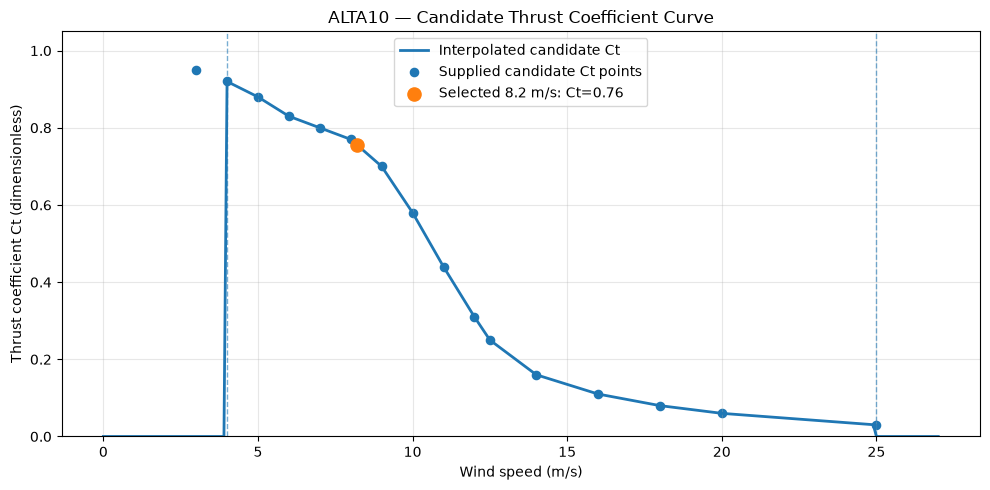

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
speeds = np.linspace(0, 27, 271)
ax.plot(speeds, get_ct(speeds), linewidth=2, label="Interpolated candidate Ct")
ax.scatter(ct_wind_speeds, ct_values, s=35, label="Supplied candidate Ct points")
ax.scatter([free_stream_speed], [thrust_coefficient], s=90, zorder=5,
           label=f"Selected {free_stream_speed:g} m/s: Ct={thrust_coefficient:.2f}")
ax.axvline(cut_in_speed, linestyle="--", linewidth=1, alpha=0.6)
ax.axvline(cut_out_speed, linestyle="--", linewidth=1, alpha=0.6)
ax.set(xlabel="Wind speed (m/s)", ylabel="Thrust coefficient Ct (dimensionless)",
       title="ALTA10 — Candidate Thrust Coefficient Curve")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Build terrain and turbine grid (UTM Zone 11N)

Calculations are performed in **meters**, EPSG:32611. Elevation comes from `elevation.tif`. This creates `farm`, `terrain`, `X`, `Y`, and `extent` for all subsequent cells.

In [6]:
farm = gpd.GeoDataFrame(
    coords.copy(),
    geometry=gpd.points_from_xy(coords["Longitude"], coords["Latitude"]),
    crs="EPSG:4326"
).to_crs("EPSG:32611")
farm["x"] = farm.geometry.x
farm["y"] = farm.geometry.y

xmin, ymin, xmax, ymax = farm.total_bounds
xmin -= padding; xmax += padding
ymin -= padding; ymax += padding
nx = int(np.ceil((xmax - xmin) / grid_resolution))
ny = int(np.ceil((ymax - ymin) / grid_resolution))
transform = from_origin(xmin, ymax, grid_resolution, grid_resolution)
terrain = np.full((ny, nx), np.nan, dtype=np.float32)

with rasterio.open(dem_path) as dem:
    reproject(
        source=rasterio.band(dem, 1),
        destination=terrain,
        src_transform=dem.transform,
        src_crs=dem.crs,
        src_nodata=dem.nodata,
        dst_transform=transform,
        dst_crs="EPSG:32611",
        dst_nodata=np.nan,
        resampling=Resampling.bilinear,
    )
    pts = farm.to_crs(dem.crs)
    samples = list(dem.sample([(p.x, p.y) for p in pts.geometry], masked=True))
    farm["elevation_m"] = [
        np.nan if np.ma.is_masked(v[0]) else float(v[0])
        for v in samples
    ]

if not np.isfinite(terrain).any():
    raise ValueError("DEM has no valid elevations in the turbine area: check coverage/CRS")
if farm["elevation_m"].isna().any():
    raise ValueError("Some turbines have missing DEM elevations: check coverage")

x = xmin + (np.arange(nx) + 0.5) * grid_resolution
y = ymax - (np.arange(ny) + 0.5) * grid_resolution
X, Y = np.meshgrid(x, y)
extent = [xmin, xmax, ymin, ymax]
print(f"Turbines: {len(farm)} | Grid: {nx} by {ny}")
print(f"Turbine elevation range: {farm.elevation_m.min():.1f}–{farm.elevation_m.max():.1f} m")

Turbines: 47 | Grid: 606 by 521
Turbine elevation range: 1048.8–1239.1 m


## 7. Wake-calculation functions

- **Jensen:** uniform top-hat deficit inside expanding wake boundary.
- **Gaussian-style:** Jensen-derived centerline deficit multiplied by a Gaussian spatial factor (not a published full Gaussian model).
- Both use a **horizontal wake centerline** with the DEM changing the vertical separation to a location's *assumed local hub height*.
- Quadratic deficit superposition; one Ct per simulation based on incoming wind speed; no terrain-following wind flow.

In [7]:
def calculate_wake_grid(model="jensen"):
    if model not in {"jensen", "gaussian_style"}:
        raise ValueError("model must be 'jensen' or 'gaussian_style'")

    theta = np.radians(wind_from_deg)
    down_x, down_y = -np.sin(theta), -np.cos(theta)
    ct = get_ct(free_stream_speed)
    deficit_sq = np.zeros(terrain.shape, dtype=np.float64)
    if ct <= 0:
        return deficit_sq

    for _, src in farm.iterrows():
        downstream = (X - src["x"]) * down_x + (Y - src["y"]) * down_y
        crosswind = -(X - src["x"]) * down_y + (Y - src["y"]) * down_x
        positive_x = np.maximum(downstream, 0.0)

        # Same hub height for all turbines: hub heights cancel in relative offset.
        vertical_offset = (terrain + hub_height) - (src["elevation_m"] + hub_height)
        center_deficit = (1 - np.sqrt(1 - ct)) / (
            1 + 2 * wake_decay * positive_x / rotor_diameter
        ) ** 2

        if model == "jensen":
            wake_radius = rotor_diameter / 2 + wake_decay * positive_x
            radial = np.hypot(crosswind, vertical_offset)
            deficit = np.where(
                (downstream > 0) & (radial <= wake_radius),
                center_deficit, 0.0
            )
        else:
            sigma = rotor_diameter / 2 + wake_decay * positive_x
            gaussian_factor = np.exp(-0.5 * (
                (crosswind / sigma) ** 2 + (vertical_offset / sigma) ** 2
            ))
            deficit = np.where(downstream > 0, center_deficit * gaussian_factor, 0.0)

        deficit[~np.isfinite(terrain)] = 0.0
        deficit_sq += deficit ** 2

    return np.minimum(np.sqrt(deficit_sq), 1.0)

jensen_deficit = calculate_wake_grid("jensen")
gaussian_deficit = calculate_wake_grid("gaussian_style")
print("Wake grids calculated. Shape:", jensen_deficit.shape)

Wake grids calculated. Shape: (521, 606)


## 8. Plot the two wake maps

Use identical wind conditions, terrain scale and wake colorbar for a fair visual comparison. The blue overlay is the **predicted percentage wind-speed deficit**, *not* a direct power-loss measurement.

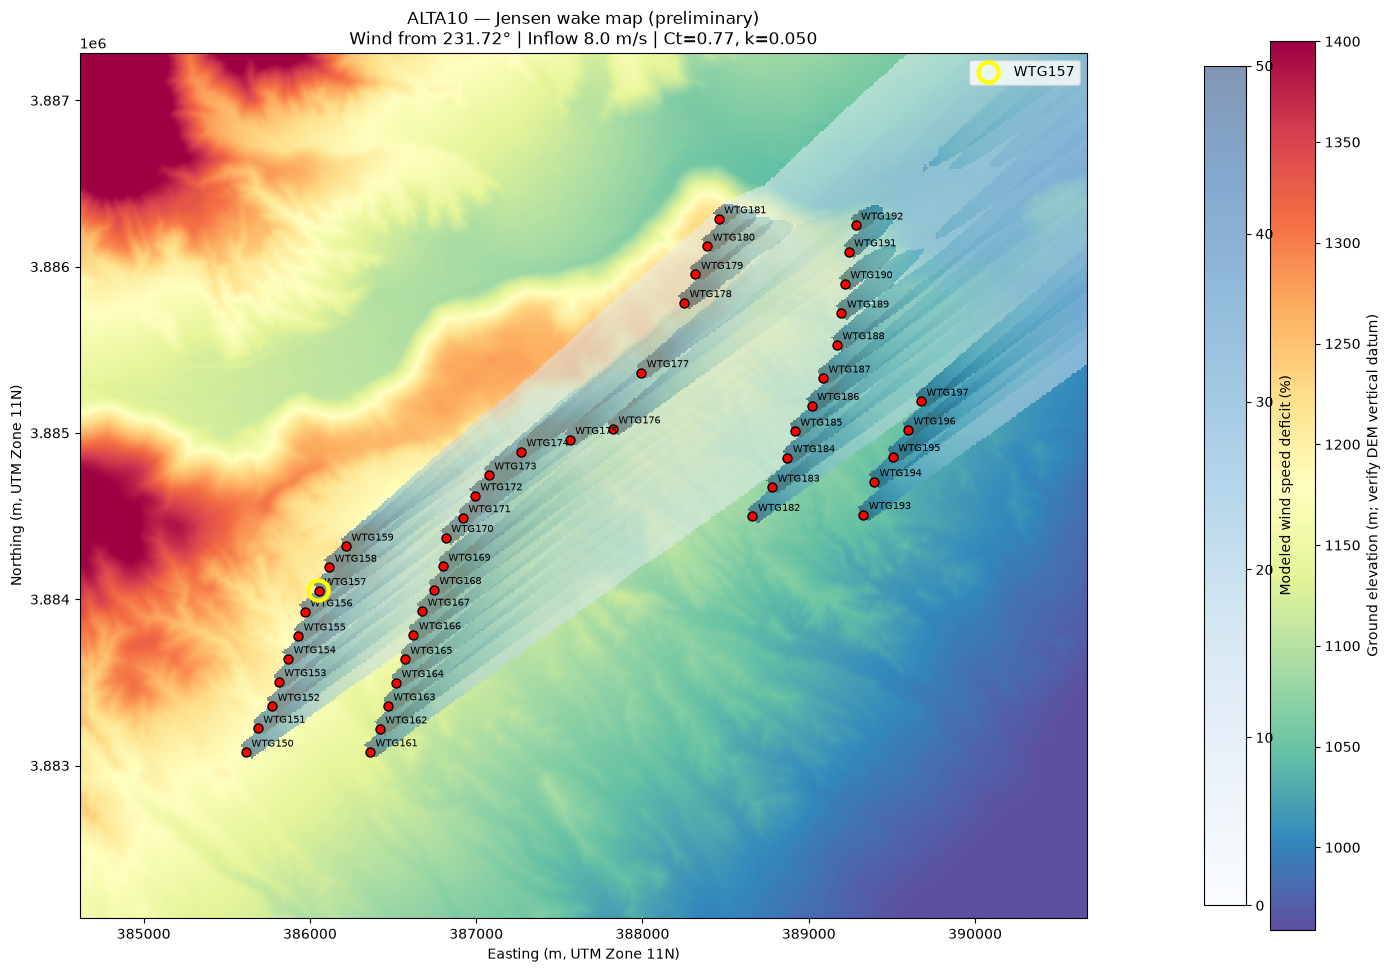

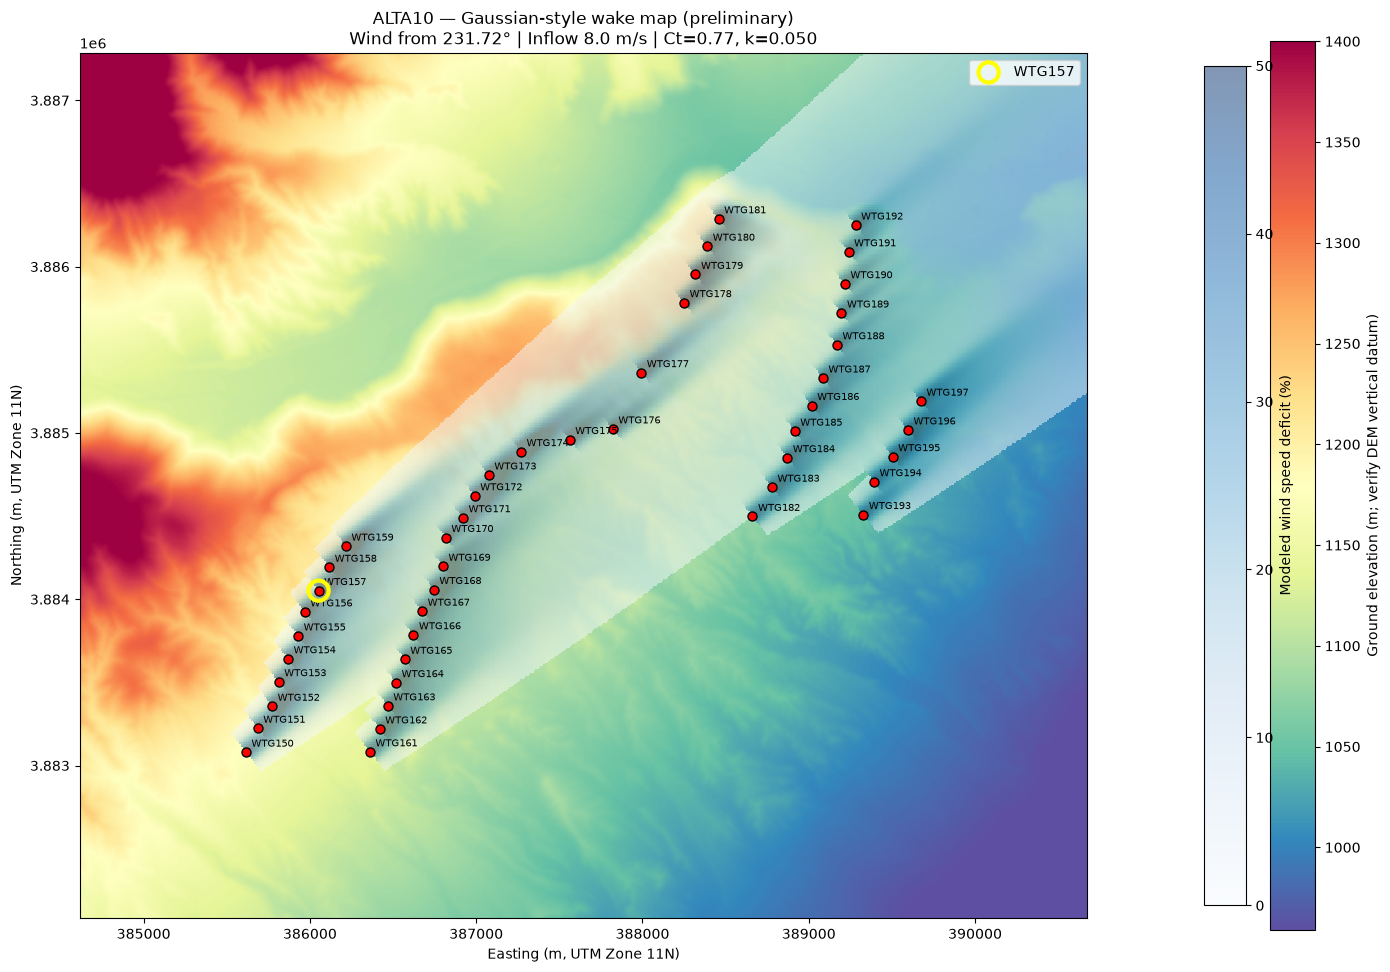

In [8]:
def plot_wake_map(deficit, model_title):
    fig, ax = plt.subplots(figsize=(14, 10))

    elev = ax.imshow(
        terrain, extent=extent, origin="upper", cmap="Spectral_r",
        vmin=np.nanpercentile(terrain, 2), vmax=np.nanpercentile(terrain, 98),
        zorder=1,
    )
    wake = np.ma.masked_where(
        (deficit < 0.01) | ~np.isfinite(terrain), deficit * 100.0
    )
    overlay = ax.imshow(
        wake, extent=extent, origin="upper", cmap="Blues",
        vmin=0, vmax=wake_color_max, alpha=0.5,
        interpolation="nearest", zorder=2,
    )
    ax.scatter(farm.x, farm.y, c="red", s=42, edgecolors="black", zorder=5)
    for _, row in farm.iterrows():
        ax.annotate(row["turbine"], (row["x"], row["y"]),
                    xytext=(4, 4), textcoords="offset points", fontsize=7, zorder=6)

    target = farm.loc[farm["turbine"] == "WTG157"]
    if not target.empty:
        ax.scatter(target.x, target.y, s=210, facecolors="none", edgecolors="yellow",
                   linewidths=3, zorder=7, label="WTG157")
        ax.legend(loc="upper right")

    bar1 = fig.colorbar(elev, ax=ax, fraction=0.036, pad=0.02)
    bar1.set_label("Ground elevation (m; verify DEM vertical datum)")
    bar2 = fig.colorbar(overlay, ax=ax, fraction=0.036, pad=0.10)
    bar2.set_label("Modeled wind speed deficit (%)")

    ax.set_title(
        f"ALTA10 — {model_title} (preliminary)\n"
        f"Wind from {wind_from_deg:.2f}° | Inflow {free_stream_speed:.1f} m/s | "
        f"Ct={get_ct(free_stream_speed):.2f}, k={wake_decay:.3f}"
    )
    ax.set_xlabel("Easting (m, UTM Zone 11N)")
    ax.set_ylabel("Northing (m, UTM Zone 11N)")
    ax.set_aspect("equal")
    fig.tight_layout()
    plt.show()

plot_wake_map(jensen_deficit, "Jensen wake map")
plot_wake_map(gaussian_deficit, "Gaussian-style wake map")

## 9. Predicted wake deficit at each turbine hub center

These are **single-condition, hub-center** predictions (no rotor averaging). No self-wakes. A zero may reflect a missed hub center even if the rotor partly overlaps a wake. Useful for identifying candidates for more detailed analysis, **not** sensor-bias estimates.

In [9]:
def turbine_wake_predictions(model="jensen"):
    if model not in {"jensen", "gaussian_style"}:
        raise ValueError("Choose 'jensen' or 'gaussian_style'")

    theta = np.radians(wind_from_deg)
    dx, dy = -np.sin(theta), -np.cos(theta)
    ct = get_ct(free_stream_speed)
    rows = []

    for _, target in farm.iterrows():
        sq = 0.0
        overlapping = 0
        for _, source in farm.iterrows():
            if source["turbine"] == target["turbine"]:
                continue
            delta_x, delta_y = target["x"] - source["x"], target["y"] - source["y"]
            downstream = delta_x * dx + delta_y * dy
            if downstream <= 0 or ct <= 0:
                continue
            crosswind = -delta_x * dy + delta_y * dx
            vert = (target["elevation_m"] + hub_height) - (source["elevation_m"] + hub_height)
            radius = rotor_diameter / 2 + wake_decay * downstream
            center = (1 - np.sqrt(1 - ct)) / (1 + 2 * wake_decay * downstream / rotor_diameter) ** 2
            if model == "jensen":
                in_wake = np.hypot(crosswind, vert) <= radius
                deficit = center if in_wake else 0.0
                overlapping += int(in_wake)
            else:
                sigma = radius
                deficit = center * np.exp(-0.5 * ((crosswind / sigma) ** 2 + (vert / sigma) ** 2))
                overlapping += int(deficit >= 0.01)  # count material contributions, not strict boundary
            sq += deficit ** 2
        combined = min(np.sqrt(sq), 1.0)
        rows.append({
            "turbine": target["turbine"],
            "model": model,
            "predicted_deficit_pct": combined * 100,
            "predicted_wind_speed_ms": free_stream_speed * (1 - combined),
            "contributing_wakes": overlapping,
        })
    return pd.DataFrame(rows)

wake_predictions = pd.concat([
    turbine_wake_predictions("jensen"),
    turbine_wake_predictions("gaussian_style")
], ignore_index=True)
display(wake_predictions.sort_values(["model", "predicted_deficit_pct"], ascending=[True, False]).head(15))
print("WTG157:")
display(wake_predictions[wake_predictions["turbine"] == "WTG157"])

,turbine,model,predicted_deficit_pct,predicted_wind_speed_ms,contributing_wakes
70,WTG174,gaussian_style,45.455423,4.363566,12
67,WTG171,gaussian_style,37.955596,4.963552,9
69,WTG173,gaussian_style,34.422922,5.246166,10
56,WTG159,gaussian_style,33.103366,5.351731,3
68,WTG172,gaussian_style,30.752279,5.539818,9
64,WTG168,gaussian_style,29.271467,5.658283,7
73,WTG177,gaussian_style,28.941193,5.684705,18
49,WTG152,gaussian_style,28.133105,5.749352,2
54,WTG157,gaussian_style,28.073653,5.754108,2
71,WTG175,gaussian_style,27.810292,5.775177,15


WTG157:


,turbine,model,predicted_deficit_pct,predicted_wind_speed_ms,contributing_wakes
7,WTG157,jensen,40.023058,4.798155,1
54,WTG157,gaussian_style,28.073653,5.754108,2


## 10. Optional comparison: wake deficit by turbine

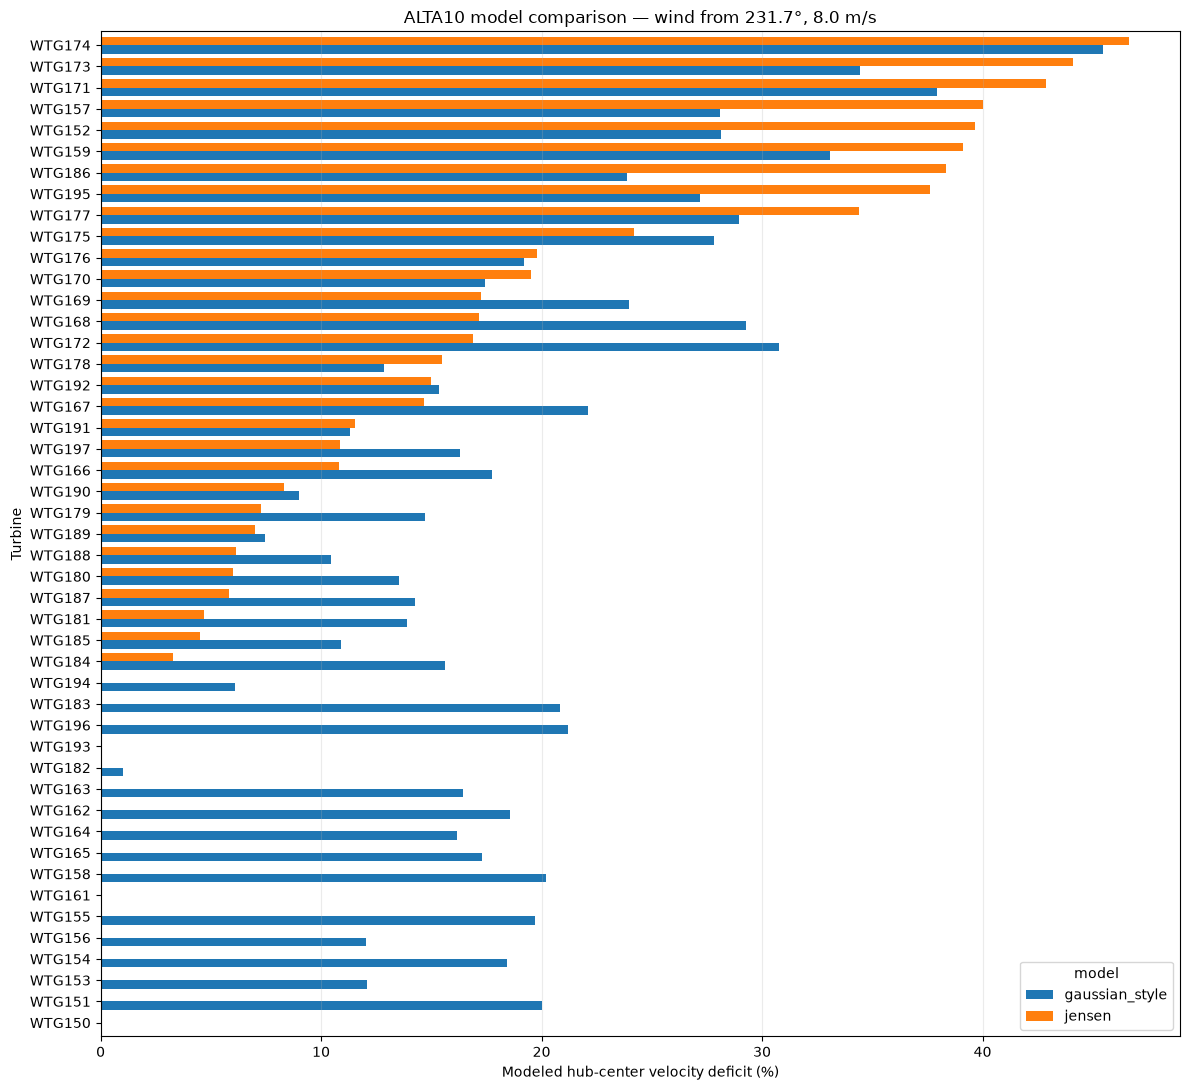

In [10]:
pivot = wake_predictions.pivot(index="turbine", columns="model", values="predicted_deficit_pct")
pivot = pivot.sort_values("jensen", ascending=True)
ax = pivot.plot.barh(figsize=(12, 11), width=0.8)
ax.set_xlabel("Modeled hub-center velocity deficit (%)")
ax.set_ylabel("Turbine")
ax.set_title(f"ALTA10 model comparison — wind from {wind_from_deg:.1f}°, {free_stream_speed:.1f} m/s")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## Next phase: anemometer-bias investigation

1. **Verify the Ct curve** with the sponsor (especially the 3 m/s vs 4 m/s cut-in discrepancy).
2. Keep `k = 0.05` as a placeholder and test sensitivity (`0.03`, `0.05`, `0.075`).
3. Obtain met-mast **10-minute wind-speed standard deviations** / turbulence intensity, an independent undisturbed inflow reference, availability/curtailment flags, and the OEM power curve.
4. Implement the published **Bastankhah–Porté-Agel Gaussian model** separately; *do not present the Gaussian-style map above as that published model*.
5. Compare wind predictions against **matched SCADA 10-minute intervals**, ideally first in clean/unwaked and steady operating periods. Nacelle anemometer readings are **not identical** to rotor-effective wind speeds; comparisons require measurement/flow corrections.

**Model caveat:** Terrain is used to adjust vertical geometry only. These maps do **not** simulate air flowing around or over the hills.